# fedOPD - how long should it train?

Two numbers in this project disagree about training length, and the disagreement has never been
resolved by measurement:

| Run | Rounds | Median MASE |
|---|---|---|
| `06_federated_forecast.ipynb` | 30 | 0.553 |
| `08_algorithm_comparison.ipynb` | 15 | **0.507** |

Same architecture, same data, same split. **Half the training gave a better result.** That is the
signature of overfitting rather than undertraining, but two points are not a curve and neither run was
designed to answer the question.

This notebook measures the whole curve.

## Two questions, and they are not the same

1. **Rounds** - how many times the server averages. Measured every round from 1 to 60.
2. **Local epochs** - how hard each site trains before reporting back. More local work per round means
   clients drift further from each other before averaging, which is a different effect from simply
   training longer.

## The honesty problem with a sweep

Choosing the round count that minimises validation error is legitimate model selection, but it
**spends validation** the way iterating spends test. After this sweep the validation figure at the
chosen point is optimistic - it is the minimum of a noisy curve, and minima of noisy curves are
biased low.

**So the deliverable here is the shape, not the winning point.** The chosen configuration is declared
in advance of looking at the test year, and the test year remains the only clean estimate. Nothing
below is scored on it.

In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path

torch.manual_seed(0)

CANON = Path("../data/canonical")
panel = pd.read_parquet(CANON / "rtt_panel.parquet")
index = pd.read_csv(CANON / "series_index.csv", parse_dates=["split_month"])

SPLIT = index.split_month.iloc[0]
H = int(index.horizon.iloc[0])
L = 24
MAX_ROUNDS = 60                                        # far past where 06 and 08 both stopped
BAND = 0.05
HIDDEN = 128

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device", device, "| scoring on the validation window starting", SPLIT.strftime("%Y-%m"))
print("sweeping to", MAX_ROUNDS, "rounds - 06 stopped at 30, 08 at 15")

device cuda | scoring on the validation window starting 2024-04
sweeping to 60 rounds - 06 stopped at 30, 08 at 15


In [2]:
wide = panel.pivot(index=["provider_code", "dept"], columns="month", values="demand")
wide = wide.loc[list(zip(index.provider_code, index.dept))]
wide.columns = pd.to_datetime(wide.columns)

train_cols = wide.columns < SPLIT
score_cols = (wide.columns >= SPLIT) & (wide.columns < SPLIT + pd.DateOffset(months=H))
assert score_cols.sum() == H, "scored window is not H months - the test year may be leaking in"

hist = wide.loc[:, train_cols].to_numpy(dtype=np.float32)
future = wide.loc[:, score_cols].to_numpy(dtype=np.float32)
scale = index.mase_scale.to_numpy()
trusts = index.provider_code.to_numpy()
norm = hist.mean(axis=1) + 1.0
month_ix = np.array([m.month - 1 for m in wide.columns[train_cols]])
eye = np.eye(12, dtype=np.float32)

clients = {}
for code in np.unique(trusts):
    rows = np.flatnonzero(trusts == code)
    xs, ys = [], []
    for r in rows:
        s = hist[r] / norm[r]
        for t in range(len(s) - L - H + 1):
            xs.append(np.concatenate([s[t:t + L], eye[month_ix[t + L - 1]]]))
            ys.append(s[t + L:t + L + H])
    clients[code] = (torch.tensor(np.array(xs)), torch.tensor(np.array(ys)), rows)

X_test = torch.tensor(np.concatenate(
    [hist[:, -L:] / norm[:, None], np.repeat(eye[month_ix[-1]][None, :], len(hist), axis=0)], axis=1))
IN_DIM = X_test.shape[1]

# a held-out slice of the TRAINING windows, used only to watch fit - never to choose anything
all_X = torch.cat([clients[c][0] for c in clients])
all_Y = torch.cat([clients[c][1] for c in clients])
print(f"{len(clients)} clients | {len(all_X):,} training windows | input dim {IN_DIM}")

141 clients | 77,145 training windows | input dim 36


In [3]:
# sums of squares for the two R-squareds, defined once
SS_POOLED = ((future - future.mean()) ** 2).sum()
SS_WITHIN = ((future - future.mean(axis=1, keepdims=True)) ** 2).sum(axis=1)
ref = hist[:, -12:].mean(axis=1)
truth_growth = future.mean(axis=1) / np.where(ref > 0, ref, np.nan) - 1
truth_up = truth_growth > BAND
base_rate = np.nanmean(truth_up) * 100

def new_model():
    return nn.Sequential(nn.Linear(IN_DIM, HIDDEN), nn.ReLU(), nn.Dropout(0.1),
                         nn.Linear(HIDDEN, HIDDEN), nn.ReLU(), nn.Linear(HIDDEN, H)).to(device)

def get_w(m): return [p.detach().clone() for p in m.parameters()]
def set_w(m, w):
    with torch.no_grad():
        for p, q in zip(m.parameters(), w): p.copy_(q)

def local_step(model, X, Y, epochs, lr=1e-3):
    model.train()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.L1Loss()
    X, Y = X.to(device), Y.to(device)
    total = 0.0
    for _ in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(X), 256):
            b = perm[i:i + 256]
            opt.zero_grad()
            loss = loss_fn(model(X[b]), Y[b])
            loss.backward(); opt.step()
            total += loss.item() * len(b)
    return total / (len(X) * epochs)

def evaluate(model):
    model.eval()
    with torch.no_grad():
        pred = np.clip(model(X_test.to(device)).cpu().numpy() * norm[:, None], 0, None)
        fit = nn.L1Loss()(model(all_X[:20000].to(device)), all_Y[:20000].to(device)).item()
    err = pred - future
    mae = np.abs(err).mean(axis=1)
    mase = np.nanmedian(np.where(scale > 0, mae / np.where(scale > 0, scale, 1), np.nan))
    rmse = np.median(np.sqrt((err ** 2).mean(axis=1)))
    ss_res = (err ** 2).sum(axis=1)
    r2p = 1 - ss_res.sum() / SS_POOLED
    r2w = np.nanmedian(np.where(SS_WITHIN > 0,
                                1 - ss_res / np.where(SS_WITHIN > 0, SS_WITHIN, 1), np.nan))
    g = pred.mean(axis=1) / np.where(ref > 0, ref, np.nan) - 1
    said = g > BAND
    ok = np.isfinite(g) & np.isfinite(truth_growth)
    prec = np.nanmean(truth_up[ok & said]) * 100 if (ok & said).sum() else np.nan
    return mase, rmse, r2p, r2w, prec, int((ok & said).sum()), fit

print(f"base rate for the up call: {base_rate:.1f}%")

base rate for the up call: 43.5%


## 1. The rounds curve

One continuous run to 60 rounds, evaluated on validation **after every round**. This is far cheaper
than 60 separate runs and gives the same curve, because FedAvg's state after round $n$ is exactly what
a run stopped at $n$ would have produced.

In [4]:
def sweep(local_epochs, max_rounds=MAX_ROUNDS):
    codes = list(clients)
    sizes = np.array([len(clients[c][0]) for c in codes], dtype=float)
    alpha = sizes / sizes.sum()
    w = get_w(new_model())
    model = new_model()
    hist_rows = []
    for r in range(1, max_rounds + 1):
        acc = [torch.zeros_like(p) for p in w]
        train_loss = 0.0
        for a, c in zip(alpha, codes):
            set_w(model, w)
            train_loss += a * local_step(model, clients[c][0], clients[c][1], local_epochs)
            for s, p in zip(acc, get_w(model)): s += a * p
        w = acc
        set_w(model, w)
        mase, rmse, r2p, r2w, prec, n_up, fit = evaluate(model)
        hist_rows.append({"local_epochs": local_epochs, "round": r, "epochs_total": r * local_epochs,
                          "val_MASE": mase, "val_RMSE": rmse, "R2_pooled": r2p, "R2_within": r2w,
                          "precision_up": prec, "n_said_up": n_up,
                          "train_loss": train_loss, "fit_loss": fit})
        if r % 10 == 0 or r == 1:
            print(f"  E={local_epochs} round {r:3d}  val MASE {mase:.4f}  prec_up {prec:5.1f}%  "
                  f"train L1 {train_loss:.4f}")
    return pd.DataFrame(hist_rows)

print("sweeping local_epochs = 2, rounds 1..60")
curve = sweep(2)

sweeping local_epochs = 2, rounds 1..60


  E=2 round   1  val MASE 3.2081  prec_up  37.5%  train L1 0.8945


  E=2 round  10  val MASE 0.5125  prec_up  68.4%  train L1 0.2522


  E=2 round  20  val MASE 0.5105  prec_up  69.4%  train L1 0.2342


  E=2 round  30  val MASE 0.5383  prec_up  68.2%  train L1 0.2262


  E=2 round  40  val MASE 0.5618  prec_up  67.6%  train L1 0.2218


  E=2 round  50  val MASE 0.5883  prec_up  68.0%  train L1 0.2179


  E=2 round  60  val MASE 0.6206  prec_up  67.5%  train L1 0.2148


In [5]:
best = curve.loc[curve.val_MASE.idxmin()]
print(f"minimum validation MASE {best.val_MASE:.4f} at round {int(best['round'])} "
      f"({int(best.epochs_total)} epochs of local work)")
print(f"  at 15 rounds (what 08 used): {curve[curve['round'] == 15].val_MASE.iloc[0]:.4f}")
print(f"  at 30 rounds (what 06 used): {curve[curve['round'] == 30].val_MASE.iloc[0]:.4f}")
print(f"  at 60 rounds               : {curve[curve['round'] == 60].val_MASE.iloc[0]:.4f}")
print()
print("training loss over the same range - if it keeps falling while validation rises, the model is")
print("fitting the training windows and not the future:")
for r in [1, 5, 10, 15, 20, 30, 45, 60]:
    row = curve[curve['round'] == r].iloc[0]
    print(f"  round {r:3d}  train L1 {row.train_loss:.4f}   val MASE {row.val_MASE:.4f}   "
          f"prec_up {row.precision_up:5.1f}%")

minimum validation MASE 0.5019 at round 13 (26 epochs of local work)
  at 15 rounds (what 08 used): 0.5072
  at 30 rounds (what 06 used): 0.5383
  at 60 rounds               : 0.6206

training loss over the same range - if it keeps falling while validation rises, the model is
fitting the training windows and not the future:
  round   1  train L1 0.8945   val MASE 3.2081   prec_up  37.5%
  round   5  train L1 0.2948   val MASE 0.5520   prec_up  51.5%
  round  10  train L1 0.2522   val MASE 0.5125   prec_up  68.4%
  round  15  train L1 0.2403   val MASE 0.5072   prec_up  70.0%
  round  20  train L1 0.2342   val MASE 0.5105   prec_up  69.4%
  round  30  train L1 0.2262   val MASE 0.5383   prec_up  68.2%
  round  45  train L1 0.2194   val MASE 0.5740   prec_up  67.5%
  round  60  train L1 0.2148   val MASE 0.6206   prec_up  67.5%


## 2. Does more *local* work help instead?

More local epochs per round is not the same as more rounds. It gives each site more gradient steps
before the server averages, so clients drift further apart between syncs - the effect FedProx exists to
control. Tested at 1, 2 and 4 local epochs over the same range of total work.

In [6]:
curves = [curve]
for e in [1, 4]:
    print(f"sweeping local_epochs = {e}")
    curves.append(sweep(e, max_rounds=MAX_ROUNDS // e if e > 1 else MAX_ROUNDS))
allc = pd.concat(curves, ignore_index=True)

print()
print("best validation MASE reached, by local-epoch setting:")
for e, g in allc.groupby("local_epochs"):
    b = g.loc[g.val_MASE.idxmin()]
    print(f"  E={e}: {b.val_MASE:.4f} at round {int(b['round'])} "
          f"({int(b.epochs_total)} total local epochs), prec_up {b.precision_up:.1f}%")

allc.to_csv(CANON / "training_length.csv", index=False)
print()
print("written: training_length.csv")

sweeping local_epochs = 1


  E=1 round   1  val MASE 3.5161  prec_up  45.0%  train L1 0.9459


  E=1 round  10  val MASE 0.5658  prec_up  53.9%  train L1 0.2915


  E=1 round  20  val MASE 0.5232  prec_up  62.6%  train L1 0.2568


  E=1 round  30  val MASE 0.5203  prec_up  66.4%  train L1 0.2475


  E=1 round  40  val MASE 0.5130  prec_up  66.8%  train L1 0.2413


  E=1 round  50  val MASE 0.5163  prec_up  65.7%  train L1 0.2383


  E=1 round  60  val MASE 0.5362  prec_up  65.4%  train L1 0.2353
sweeping local_epochs = 4


  E=4 round   1  val MASE 2.1259  prec_up  29.5%  train L1 0.8243


  E=4 round  10  val MASE 0.5316  prec_up  68.5%  train L1 0.2287



best validation MASE reached, by local-epoch setting:
  E=1: 0.5088 at round 35 (35 total local epochs), prec_up 67.1%
  E=2: 0.5019 at round 13 (26 total local epochs), prec_up 70.3%
  E=4: 0.5040 at round 6 (24 total local epochs), prec_up 68.0%

written: training_length.csv


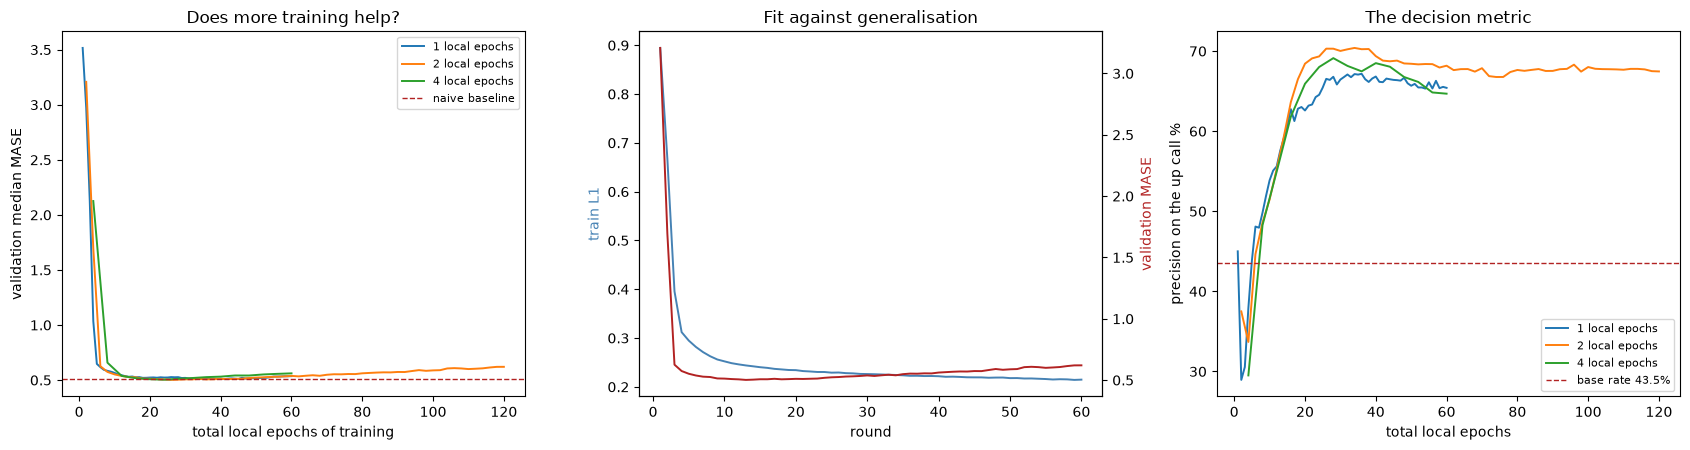

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
NAIVE = 0.510                                          # the baseline from 05, on this same window

for e, g in allc.groupby("local_epochs"):
    ax[0].plot(g.epochs_total, g.val_MASE, lw=1.4, label=f"{e} local epochs")
ax[0].axhline(NAIVE, color="firebrick", ls="--", lw=1, label="naive baseline")
ax[0].set_xlabel("total local epochs of training"); ax[0].set_ylabel("validation median MASE")
ax[0].set_title("Does more training help?"); ax[0].legend(fontsize=8)

g2 = allc[allc.local_epochs == 2]
ax[1].plot(g2["round"], g2.train_loss, lw=1.4, color="steelblue", label="training loss")
ax[1].set_xlabel("round"); ax[1].set_ylabel("train L1", color="steelblue")
ax2 = ax[1].twinx()
ax2.plot(g2["round"], g2.val_MASE, lw=1.4, color="firebrick", label="validation MASE")
ax2.set_ylabel("validation MASE", color="firebrick")
ax[1].set_title("Fit against generalisation")

for e, g in allc.groupby("local_epochs"):
    ax[2].plot(g.epochs_total, g.precision_up, lw=1.4, label=f"{e} local epochs")
ax[2].axhline(base_rate, color="firebrick", ls="--", lw=1, label=f"base rate {base_rate:.1f}%")
ax[2].set_xlabel("total local epochs"); ax[2].set_ylabel("precision on the up call %")
ax[2].set_title("The decision metric"); ax[2].legend(fontsize=8)
plt.tight_layout()

## What to take from this

The curve answers the question directly, and it answers it for **both** metrics, which matters because
this project has already found once that they disagree.

**If validation error falls and then rises** while training loss keeps falling, the model is fitting
the training windows rather than the future, and the right round count is the turning point --- more
training is actively harmful, not merely wasteful.

**If validation error is flat within noise** across the whole range, then training length was never the
explanation for anything, and both the 0.553 and the 0.507 are draws from the same distribution. That
would make the difference between `06` and `08` noise rather than a finding, and Finding 5 in the
report would need weakening.

Either way the conclusion is a measurement rather than an argument, and it is reported as the whole
curve rather than as its best point.